## Ćwiczenie 6: Filtry wyostrzające i detekcja krawędzi w medycynie
### Część 2: Operatory Sobela, Prewitta oraz LoG (Laplacian of Gaussian)

1. Praktyczne zastosowanie kierunkowych operatorów pierwszego rzędu (Sobel, Prewitt) do wykrywania granic struktur anatomicznych.
2. Zbadanie wrażliwości operatorów drugiego rzędu (Laplasjan) na szum.
3. Implementacja hybrydowego filtru **LoG (Laplacian of Gaussian)** jako bezpiecznego standardu medycznej detekcji krawędzi.

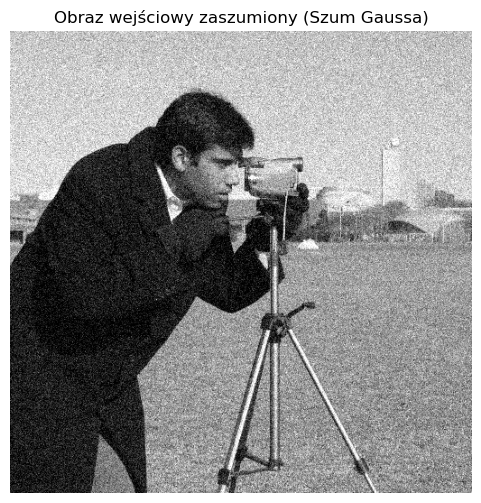

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, filters, util

# 1. Wczytanie obrazu referencyjnego i normalizacja do zakresu [0, 1]
# Używamy obrazu z wbudowanej bazy skimage 
image = data.camera() / 255.0
#image = data.shepp_logan_phantom() 
#image = data.horse() 
#image = data.astronaut()

# 2. Celowe dodanie szumu Gaussa, aby sprawdzić odporność algorytmów
noisy_image = util.random_noise(image, mode='gaussian', var=0.01)

# Wyświetlenie obrazu wejściowego
plt.figure(figsize=(6, 6))
plt.imshow(noisy_image, cmap='gray')
plt.title('Obraz wejściowy zaszumiony (Szum Gaussa)')
plt.axis('off')
plt.show()

### Zadanie 1: Operatory Sobela i Prewitta

#### Animzacja detekcji krawędzi

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation

# 1. Przygotowanie obrazu ze sztuczną pionową krawędzią (np. przejście z 0.2 do 0.8)
image = np.full((10, 10), 0.2)
image[:, 5:] = 0.8  # Pionowa krawędź dokładnie między kolumną 4 a 5

# 2. Maska Prewitta dla krawędzi pionowych (H_x)
kernel_prewitt_x = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
])

# 3. Obliczenie pełnego splotu dla celów referencyjnych (wynik)
pad_img = np.pad(image, pad_width=1, mode='edge')
conv_result = np.zeros_like(image)

for r in range(image.shape[0]):
    for c in range(image.shape[1]):
        region = pad_img[r:r+3, c:c+3]
        conv_result[r, c] = np.sum(region * kernel_prewitt_x)

# 4. Tworzenie figur do animacji
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5))

# Wyświetlenie obrazu wejściowego
im1 = ax1.imshow(image, cmap='gray', vmin=0, vmax=1)
ax1.set_title("Obraz wejściowy (Pionowa krawędź)")
ax1.set_xticks(range(10))
ax1.set_yticks(range(10))

# Wyświetlenie macierzy wynikowej (inicjalnie pusta)
result_display = np.full_like(conv_result, np.nan)
im2 = ax2.imshow(result_display, cmap='gray', vmin=-2, vmax=2)
ax2.set_title("Wynik splotu z maską Prewitt H_x")
ax2.set_xticks(range(10))
ax2.set_yticks(range(10))

# Zaznaczenie okna maski (3x3) na obrazie wejściowym
rect = plt.Rectangle((0 - 0.5, 4 - 0.5), 3, 3, fill=False, edgecolor='red', lw=2)
ax1.add_patch(rect)

# Krok animacji: przesuwamy maskę wzdłuż jednego wiersza (np. wiersz 4) przez wszystkie kolumny
def update(col):
    row = 4
    rect.set_xy((col - 0.5, row - 0.5))
    
    # Aktualizacja wyników na nowej macierzy
    result_display[row, col] = conv_result[row, col]
    im2.set_data(result_display)
    
    ax1.set_title(f"Maska w wierszu {row}, kolumnie {col}\nSuma splotu = {conv_result[row, col]:.2f}")
    return im1, im2, rect

# Tworzenie animacji (przesuwamy się po kolumnach od 0 do 9)
ani = animation.FuncAnimation(
    fig, update, frames=range(10), interval=800, repeat=True
)

plt.close(fig)

# Wyświetlenie interaktywnego odtwarzacza w Jupyter Notebooku
from IPython.display import HTML
HTML(ani.to_jshtml())

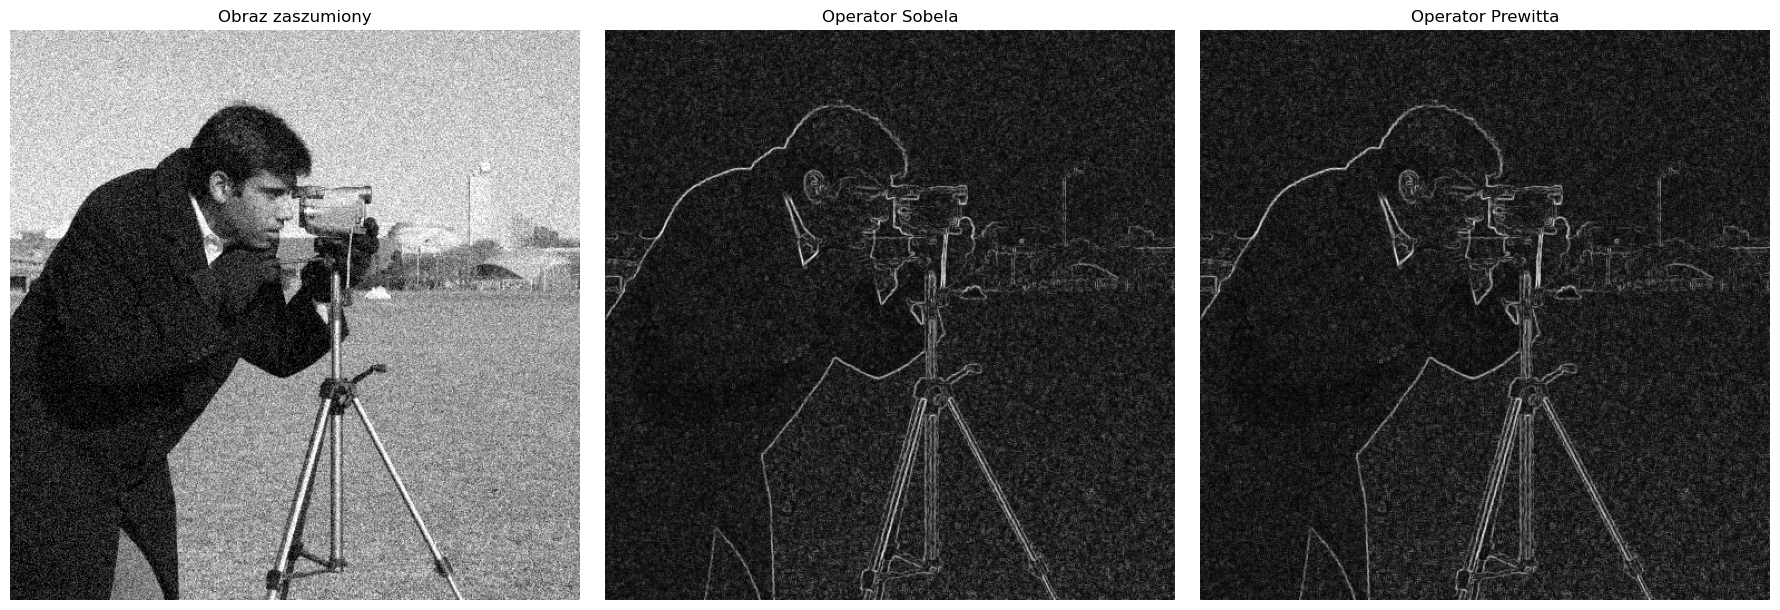

In [29]:
# Obliczanie gradientów przy użyciu funkcji z biblioteki scikit-image
sobel_edge = filters.sobel(noisy_image)
prewitt_edge = filters.prewitt(noisy_image)

# Wizualizacja porównawcza
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(noisy_image, cmap='gray')
axes[0].set_title('Obraz zaszumiony')

axes[1].imshow(sobel_edge, cmap='gray')
axes[1].set_title('Operator Sobela')

axes[2].imshow(prewitt_edge, cmap='gray')
axes[2].set_title('Operator Prewitta')

for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

### Zadanie 2: Pułapka szumu w operatorze Laplace'a
Czysty Laplasjan oblicza drugą pochodną i jest niezwykle wrażliwny na gwałtowne zmiany spowodowane szumem. Zobaczmy, co stanie się, gdy zastosujemy go bezpośrednio na zaszumiony obraz.

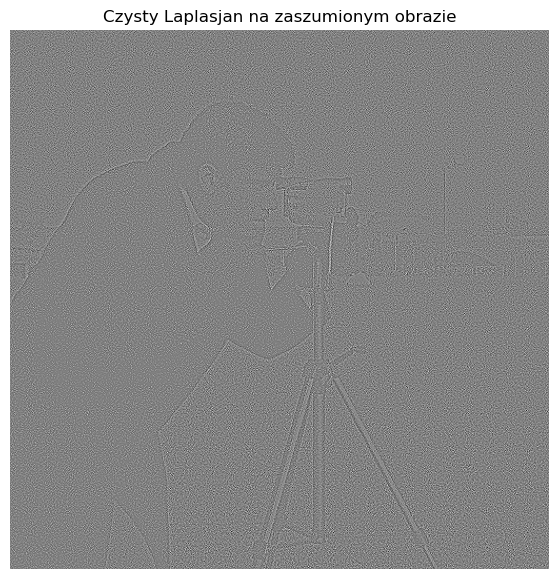

In [34]:
# Zastosowanie czystego Laplasjana bezpośrednio na zaszumiony obraz
laplace_raw = filters.laplace(noisy_image)

plt.figure(figsize=(7, 7))
plt.imshow(laplace_raw, cmap='gray')
plt.title('Czysty Laplasjan na zaszumionym obrazie')
plt.axis('off')
plt.show()

### Zadanie 3: Rozwiązanie – Filtr LoG (Laplacian of Gaussian)
Aby ominąć problem wrażliwości na szum, stosujemy podejście dwuetapowe:
1. **Wygładzanie Gaussem** (usuwa wysoki częstotliwościowo szum).
2. **Laplasjan** (wykrywa czyste, wygładzone krawędzie).

W `scikit-image` mamy gotową funkcję `filters.laplace(filters.gaussian(...))` lub dedykowaną implementację.

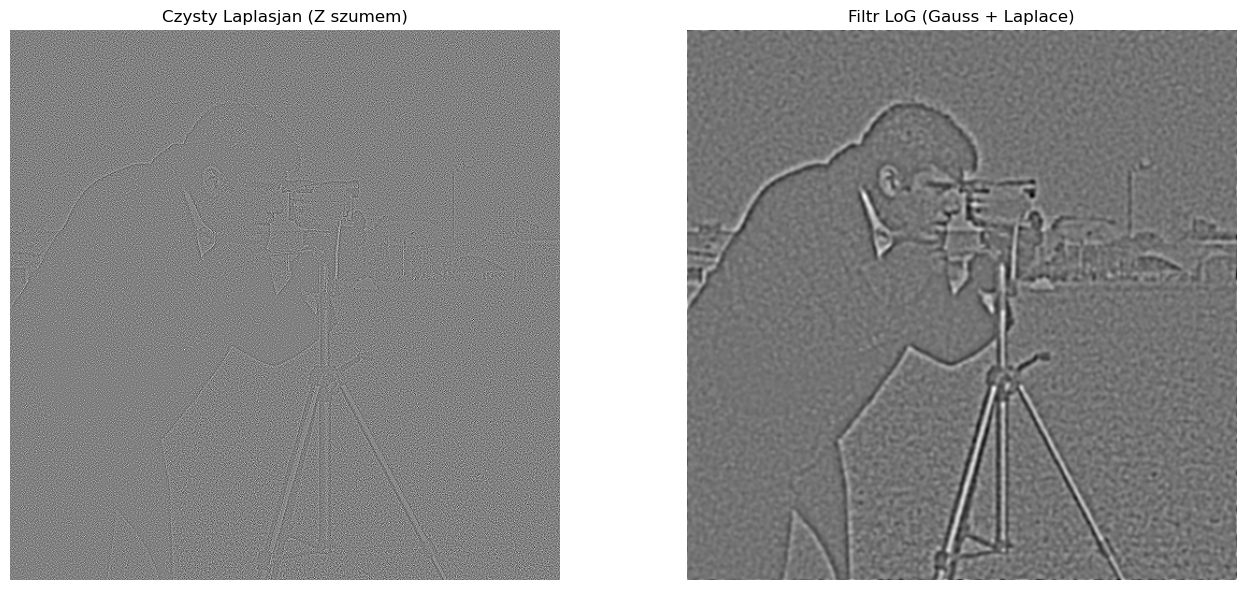

In [37]:
# Krok 1: Wygładzenie wstępne filtrem Gaussa (sigma = 2.0)
smoothed_for_laplace = filters.gaussian(noisy_image, sigma=2.0)

# Krok 2: Zastosowanie Laplasjana na wygładzonym obrazie (LoG)
log_edge = filters.laplace(smoothed_for_laplace)

# Wizualizacja porównawcza efektu LoG
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(laplace_raw, cmap='gray')
axes[0].set_title('Czysty Laplasjan (Z szumem)')

axes[1].imshow(log_edge, cmap='gray')
axes[1].set_title('Filtr LoG (Gauss + Laplace)')

for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

### Podsumowanie i Wnioski do dyskusji:
1. Operatory Sobela i Prewitta radzą sobie dobrze z umiarkowanym szumem dzięki wbudowanemu uśrednianiu kierunkowemu.
2. Czysty Laplasjan bez uprzedniego wygładzenia jest całkowicie bezużyteczny w diagnostyce medycznej z powodu dominacji szumu.
3. Połączenie Gaussa i Laplace'a (**LoG**) pozwala precyzyjnie wyznaczyć punkty zerowe drugiej pochodnej, co stanowi potężne narzędzie do automatycznego obrysowywania (segmentacji) granic narządów wewnętrznych.